# LSTM Baseline Model (L0)

## Objective
Establish a baseline for English-to-French translation using an LSTM encoder–decoder architecture without attention.

## Architecture
- Encoder: one LSTM layer
- Decoder: one LSTM layer
- English embedding dimension: 128
- French embedding dimension: 128
- Hidden dimension: 256
- Dropout: 0.2

## Training Configuration
- Optimizer: Adam
- Initial learning rate: 0.001
- Weight decay: 0.00001
- Batch size: 64
- Maximum epochs: 20
- Loss: Cross-entropy, ignoring French padding tokens
- Gradient clipping: maximum norm 1.0
- Scheduler: ReduceLROnPlateau

## Objective of the Experiment
Compare the LSTM baseline against the GRU baseline using validation loss, token accuracy, training time, parameter count, and eventually generated translation quality.

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
# 1. Import necessary libraries
import sys
import json
import time
from pathlib import Path

import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from torch.utils.data import TensorDataset, DataLoader
from tokenizers import Tokenizer

In [5]:
%cd /content/drive/MyDrive/english-french-machine-translation/english-french-machine-translation

/content/drive/MyDrive/english-french-machine-translation/english-french-machine-translation


In [6]:
%ls -la

total 34
drwx------ 6 root root 4096 Oct 12 09:24 ./
drwx------ 3 root root 4096 Oct 12 09:02 ../
drwx------ 2 root root 4096 Oct 12 10:32 data/
drwx------ 2 root root 4096 Oct 12 09:24 .git/
-rw------- 1 root root    0 Oct 12 09:28 .gitignore
drwx------ 2 root root 4096 Oct 12 09:28 notebooks/
-rw------- 1 root root 5120 Oct 12 09:33 README.md
drwx------ 2 root root 4096 Oct 12 09:28 src/
-rw------- 1 root root 5120 Oct 12 09:32 utils


In [7]:
print(Path.cwd())

/content/drive/MyDrive/english-french-machine-translation/english-french-machine-translation


In [8]:
PROJECT_ROOT = Path.cwd()

DATA_DIR = PROJECT_ROOT / "data"
PROCESSED_DIR = DATA_DIR / "processed"
SRC_DIR = PROJECT_ROOT / "src"

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Project root:", PROJECT_ROOT)
print("Data directory:", DATA_DIR)
print("Source directory:", SRC_DIR)
print("Device:", device)

Project root: /content/drive/MyDrive/english-french-machine-translation/english-french-machine-translation
Data directory: /content/drive/MyDrive/english-french-machine-translation/english-french-machine-translation/data
Source directory: /content/drive/MyDrive/english-french-machine-translation/english-french-machine-translation/src
Device: cuda


In [9]:
# Load processed data
tensor_path = PROCESSED_DIR / "translation_ids.pt"

data = torch.load(
    tensor_path,
    map_location="cpu",
    weights_only=True
)

X_train = data["X_train"]
y_train = data["y_train"]

X_val = data["X_val"]
y_val = data["y_val"]

X_test = data["X_test"]
y_test = data["y_test"]


# Load tokenizers
en_tokenizer = Tokenizer.from_file(
    str(PROCESSED_DIR / "english_tokenizer.json")
)

fr_tokenizer = Tokenizer.from_file(
    str(PROCESSED_DIR / "french_tokenizer.json")
)


# Load preprocessing configuration
with open(
    PROCESSED_DIR / "preprocessing_config.json",
    "r",
    encoding="utf-8"
) as file:
    config = json.load(file)


print("Data loaded successfully.")
print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)
print("English vocabulary:", en_tokenizer.get_vocab_size())
print("French vocabulary:", fr_tokenizer.get_vocab_size())
print("Configuration:", config)

Data loaded successfully.
Training: torch.Size([133704, 20]) torch.Size([133704, 22])
Validation: torch.Size([16713, 20]) torch.Size([16713, 22])
Test: torch.Size([16713, 20]) torch.Size([16713, 22])
English vocabulary: 14493
French vocabulary: 23539
Configuration: {'english_max_length': 20, 'french_max_length': 22, 'english_vocab_size': 14493, 'french_vocab_size': 23539, 'pad_token': '[PAD]', 'unk_token': '[UNK]', 'bos_token': '[BOS]', 'eos_token': '[EOS]'}


In [10]:
# Retrieve special token IDs
en_pad_id = en_tokenizer.token_to_id("[PAD]")
fr_pad_id = fr_tokenizer.token_to_id("[PAD]")

en_unk_id = en_tokenizer.token_to_id("[UNK]")
fr_unk_id = fr_tokenizer.token_to_id("[UNK]")

en_bos_id = en_tokenizer.token_to_id("[BOS]")
fr_bos_id = fr_tokenizer.token_to_id("[BOS]")

en_eos_id = en_tokenizer.token_to_id("[EOS]")
fr_eos_id = fr_tokenizer.token_to_id("[EOS]")


# Create datasets
train_dataset = TensorDataset(X_train, y_train)
val_dataset = TensorDataset(X_val, y_val)
test_dataset = TensorDataset(X_test, y_test)


# Create data loaders
BATCH_SIZE = 64

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)


# Import shared utilities
from src.utils import train_model, plot_training_history, evaluate_model


# Verify
print("English PAD ID:", en_pad_id)
print("French PAD ID:", fr_pad_id)
print("French BOS ID:", fr_bos_id)
print("French EOS ID:", fr_eos_id)

print("\nTraining batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

source_batch, target_batch = next(iter(train_loader))

print("\nSource batch shape:", source_batch.shape)
print("Target batch shape:", target_batch.shape)

English PAD ID: 1
French PAD ID: 1
French BOS ID: 2
French EOS ID: 3

Training batches: 2090
Validation batches: 262
Test batches: 262

Source batch shape: torch.Size([64, 20])
Target batch shape: torch.Size([64, 22])


In [11]:
# Encoder class

class Encoder(nn.Module):

    def __init__(
        self,
        vocab_size,
        embedding_dim,
        hidden_dim,
        num_layers,
        padding_idx
    ):
        super().__init__()

        self.embedding = nn.Embedding(
            num_embeddings=vocab_size,
            embedding_dim=embedding_dim,
            padding_idx=padding_idx,
        )

        self.lstm = nn.LSTM(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True
        )

    def forward(self, input_ids, lengths):
        embedded = self.embedding(input_ids)

        packed = nn.utils.rnn.pack_padded_sequence(
            embedded,
            lengths.cpu(),
            batch_first=True,
            enforce_sorted=False
        )

        packed_outputs, (hidden, cell) = self.lstm(packed)

        outputs, _ = nn.utils.rnn.pad_packed_sequence(
            packed_outputs,
            batch_first=True,
            total_length=input_ids.shape[1]
        )

        return outputs, (hidden, cell)

In [12]:
# Decoder class

class Decoder(nn.Module):

    def __init__(
        self,
        vocab_size,
        embedding_dim,
        hidden_dim,
        num_layers,
        padding_idx,
        dropout_rate=0.2
    ):
        super().__init__()

        # Convert French token IDs into vectors
        self.embedding = nn.Embedding(
            num_embeddings=vocab_size,
            embedding_dim=embedding_dim,
            padding_idx=padding_idx,
        )

        # Process the French sequence
        self.lstm = nn.LSTM(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
        )

        # Dropout before the output projection
        self.dropout = nn.Dropout(dropout_rate)

        # Convert each LSTM output into vocabulary scores
        self.fc = nn.Linear(
            in_features=hidden_dim,
            out_features=vocab_size,
        )

    def forward(self, input_ids, state):
        # Unpack the encoder's hidden and cell states
        hidden, cells = state

        # (batch_size, target_length, embedding_dim)
        embedded = self.embedding(input_ids)

        # Process the sequence using both initial states
        outputs, (hidden, cells) = self.lstm(
            embedded,
            (hidden, cells)
        )

        # Apply dropout to LSTM outputs
        outputs = self.dropout(outputs)

        # (batch_size, target_length, vocab_size)
        logits = self.fc(outputs)

        return logits, (hidden, cells)

In [13]:
# Seq2Seq class

class Seq2Seq(nn.Module):
    def __init__(self, encoder, decoder):
        super().__init__()

        self.encoder = encoder
        self.decoder = decoder

    def forward(self, source_ids, source_lengths, target_ids):
        # Encode the English sentences
        encoder_outputs, (encoder_hidden, encoder_cell) = self.encoder(
            source_ids,
            source_lengths,
        )

        # Initialize the decoder with both encoder states
        logits, (decoder_hidden, decoder_cell) = self.decoder(
            target_ids,
            (encoder_hidden, encoder_cell),
        )

        return logits

# Experiment E0: LSTM Baseline

## 1. Objective

The objective of Experiment E0 is to establish a baseline for the LSTM encoder–decoder architecture on the English–French machine translation task. The experiment evaluates how well the LSTM model learns to generate French sequences from English input sentences using teacher forcing.

This baseline will serve as the reference point for the subsequent LSTM experiments and for comparison with the GRU architecture.

## 2. Model Architecture

The model consists of an LSTM encoder and an LSTM decoder connected through their hidden and cell states.

- **Encoder:** Converts English token IDs into embeddings and processes the sequence using an LSTM.
- **Decoder:** Processes French input tokens using an LSTM initialized with the encoder's final hidden and cell states.
- **Output projection:** A linear layer transforms each decoder output into scores over the French vocabulary.
- **Attention:** Not used in this experiment.

The encoder uses packed sequences to avoid processing padded English tokens. The decoder uses dropout before the output projection.

## 3. Experimental Configuration

| Parameter | Configuration |
|---|---|
| Embedding dimension | 128 |
| Hidden dimension | 256 |
| Encoder layers | 1 |
| Decoder layers | 1 |
| Dropout | 0.2 |
| Batch size | 64 |
| Optimizer | Adam |
| Initial learning rate | 0.001 |
| Weight decay | 0.00001 |
| Loss function | Cross-entropy loss |
| Padding treatment | French PAD tokens ignored in loss and accuracy |
| Gradient clipping | Maximum norm of 1.0 |
| Learning-rate scheduler | ReduceLROnPlateau |
| Maximum epochs | 20 |
| Training strategy | Teacher forcing |

## 4. Dataset and Preprocessing

The experiment reuses the processed English–French dataset and the existing tokenizers from the preprocessing notebook.

The data splits remain unchanged:

- Training set: 133,704 sentence pairs
- Validation set: 16,713 sentence pairs
- Test set: 16,713 sentence pairs

The English input tensors have a sequence length of 20, while the French target tensors have a sequence length of 22.

The same splits, tokenization, padding, and special-token conventions are maintained across the GRU and LSTM experiments to support a consistent comparison.

## 5. Training Procedure

During training, the English sentences are passed through the encoder to obtain the final hidden and cell states. These states initialize the decoder, which receives the shifted French target sequence as input under teacher forcing.

The model produces vocabulary logits at each target position. Cross-entropy loss is calculated against the shifted French targets, excluding padding positions.

The training procedure includes gradient clipping and a ReduceLROnPlateau scheduler that adjusts the learning rate based on validation loss.

Training and validation loss and token accuracy are recorded at each epoch. The best model checkpoint should be selected using validation performance and retained for final test evaluation.

## 6. Evaluation

The model is evaluated using:

- Training loss and token accuracy
- Validation loss and token accuracy
- Test loss and token accuracy

Token accuracy measures the proportion of non-padding target tokens predicted correctly under teacher forcing. It does not directly measure complete-sentence translation quality.

The test set is reserved for final evaluation after model selection using the validation set.

## 7. Expected Outcome

This experiment establishes the baseline performance of the LSTM encoder–decoder model using one recurrent layer in each component, an embedding dimension of 128, and a hidden dimension of 256.

The results will be used to assess whether increasing recurrent depth in E1 or increasing the embedding dimension in E2 provides an improvement over the baseline.

## 8. Reproducibility

The dataset splits, preprocessing artifacts, model configuration, optimizer settings, and evaluation procedure should remain consistent across experiments.

The random seed, best validation epoch, saved checkpoint, training history, and final test metrics should be recorded to support reproducibility and fair comparison with the GRU experiments.


In [14]:
# ==========================================
# LSTM EXPERIMENT CONFIGURATION
# ==========================================

# Experiment selection
EXPERIMENT = "E0"

# Data configuration
BATCH_SIZE = 64

# Model configuration
EMBEDDING_DIM = 128
HIDDEN_DIM = 256
NUM_LAYERS = 1
DROPOUT_RATE = 0.2

# Training configuration
NUM_EPOCHS = 20
LEARNING_RATE = 0.001
WEIGHT_DECAY = 1e-5
GRAD_CLIP = 1.0

# Learning-rate scheduler configuration
SCHEDULER_FACTOR = 0.8
SCHEDULER_PATIENCE = 3
MIN_LEARNING_RATE = 1e-6

# Special token IDs
EN_PAD_ID = en_tokenizer.token_to_id("[PAD]")
FR_PAD_ID = fr_tokenizer.token_to_id("[PAD]")
FR_BOS_ID = fr_tokenizer.token_to_id("[BOS]")
FR_EOS_ID = fr_tokenizer.token_to_id("[EOS]")

# Vocabulary sizes
EN_VOCAB_SIZE = en_tokenizer.get_vocab_size()
FR_VOCAB_SIZE = fr_tokenizer.get_vocab_size()

# Device
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print(f"Experiment: {EXPERIMENT}")
print(f"Device: {device}")
print(f"English vocabulary: {EN_VOCAB_SIZE}")
print(f"French vocabulary: {FR_VOCAB_SIZE}")

Experiment: E0
Device: cuda
English vocabulary: 14493
French vocabulary: 23539


In [18]:
# ==========================================
# MODEL INSTANTIATION
# ==========================================

# Encoder
encoder = Encoder(
    vocab_size=EN_VOCAB_SIZE,
    embedding_dim=EMBEDDING_DIM,
    hidden_dim=HIDDEN_DIM,
    num_layers=NUM_LAYERS,
    padding_idx=EN_PAD_ID
)

# Decoder
decoder = Decoder(
    vocab_size=FR_VOCAB_SIZE,
    embedding_dim=EMBEDDING_DIM,
    hidden_dim=HIDDEN_DIM,
    num_layers=NUM_LAYERS,
    padding_idx=FR_PAD_ID,
    dropout_rate=DROPOUT_RATE
)

# Combine encoder and decoder
model = Seq2Seq(
    encoder=encoder,
    decoder=decoder
).to(device)

# Count trainable parameters
total_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

print(model)
print(f"\nExperiment: {EXPERIMENT}")
print(f"Device: {device}")
print(f"Trainable parameters: {total_parameters:,}")

Seq2Seq(
  (encoder): Encoder(
    (embedding): Embedding(14493, 128, padding_idx=1)
    (lstm): LSTM(128, 256, batch_first=True)
  )
  (decoder): Decoder(
    (embedding): Embedding(23539, 128, padding_idx=1)
    (lstm): LSTM(128, 256, batch_first=True)
    (dropout): Dropout(p=0.2, inplace=False)
    (fc): Linear(in_features=256, out_features=23539, bias=True)
  )
)

Experiment: E0
Device: cuda
Trainable parameters: 11,708,147


In [19]:
# ==========================================
# LOSS FUNCTION AND OPTIMIZER
# ==========================================

criterion = nn.CrossEntropyLoss(
    ignore_index=FR_PAD_ID
)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

print("Loss function:", criterion)
print("Optimizer:", optimizer)

Loss function: CrossEntropyLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 1e-05
)


In [20]:
# ==========================================
# LEARNING-RATE SCHEDULER
# ==========================================

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=SCHEDULER_FACTOR,
    patience=SCHEDULER_PATIENCE,
    min_lr=MIN_LEARNING_RATE
)

print("Scheduler:", scheduler)

Scheduler: <torch.optim.lr_scheduler.ReduceLROnPlateau object at 0x7fe95a781be0>


In [21]:
# ==========================================
# FORWARD-PASS SHAPE CHECK
# ==========================================

source_ids, target_ids = next(iter(train_loader))

source_ids = source_ids.to(device)
target_ids = target_ids.to(device)

source_lengths = (
    source_ids != EN_PAD_ID
).sum(dim=1)

# Teacher-forcing inputs and expected targets
decoder_input = target_ids[:, :-1]
expected_targets = target_ids[:, 1:]

model.eval()

with torch.no_grad():
    logits = model(
        source_ids,
        source_lengths,
        decoder_input
    )

print("Source shape:", source_ids.shape)
print("Decoder input shape:", decoder_input.shape)
print("Expected target shape:", expected_targets.shape)
print("Logits shape:", logits.shape)

assert logits.shape[:2] == expected_targets.shape
assert logits.shape[-1] == FR_VOCAB_SIZE

print("\nForward-pass shape check passed.")

Source shape: torch.Size([64, 20])
Decoder input shape: torch.Size([64, 21])
Expected target shape: torch.Size([64, 21])
Logits shape: torch.Size([64, 21, 23539])

Forward-pass shape check passed.


In [22]:
# ==========================================
# TRAIN LSTM BASELINE — E0
# ==========================================

history_e0 = train_model(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    optimizer=optimizer,
    criterion=criterion,
    scheduler=scheduler,
    num_epochs=NUM_EPOCHS,
    en_pad_id=EN_PAD_ID,
    fr_pad_id=FR_PAD_ID,
    device=device
)

Epoch [1/20] Train Loss: 3.4100 | Val Loss: 2.5878 | Train Acc: 44.79% | Val Acc: 53.98% | LR: 0.001
Epoch [2/20] Train Loss: 2.3522 | Val Loss: 2.1049 | Train Acc: 56.27% | Val Acc: 60.16% | LR: 0.001
Epoch [3/20] Train Loss: 1.9596 | Val Loss: 1.8462 | Train Acc: 61.43% | Val Acc: 64.14% | LR: 0.001
Epoch [4/20] Train Loss: 1.7110 | Val Loss: 1.6718 | Train Acc: 65.10% | Val Acc: 67.07% | LR: 0.001
Epoch [5/20] Train Loss: 1.5408 | Val Loss: 1.5642 | Train Acc: 67.82% | Val Acc: 68.95% | LR: 0.001
Epoch [6/20] Train Loss: 1.4161 | Val Loss: 1.4829 | Train Acc: 69.86% | Val Acc: 70.36% | LR: 0.001
Epoch [7/20] Train Loss: 1.3236 | Val Loss: 1.4317 | Train Acc: 71.45% | Val Acc: 71.18% | LR: 0.001
Epoch [8/20] Train Loss: 1.2515 | Val Loss: 1.3884 | Train Acc: 72.70% | Val Acc: 71.93% | LR: 0.001
Epoch [9/20] Train Loss: 1.1933 | Val Loss: 1.3598 | Train Acc: 73.76% | Val Acc: 72.48% | LR: 0.001
Epoch [10/20] Train Loss: 1.1461 | Val Loss: 1.3361 | Train Acc: 74.56% | Val Acc: 72.81% |

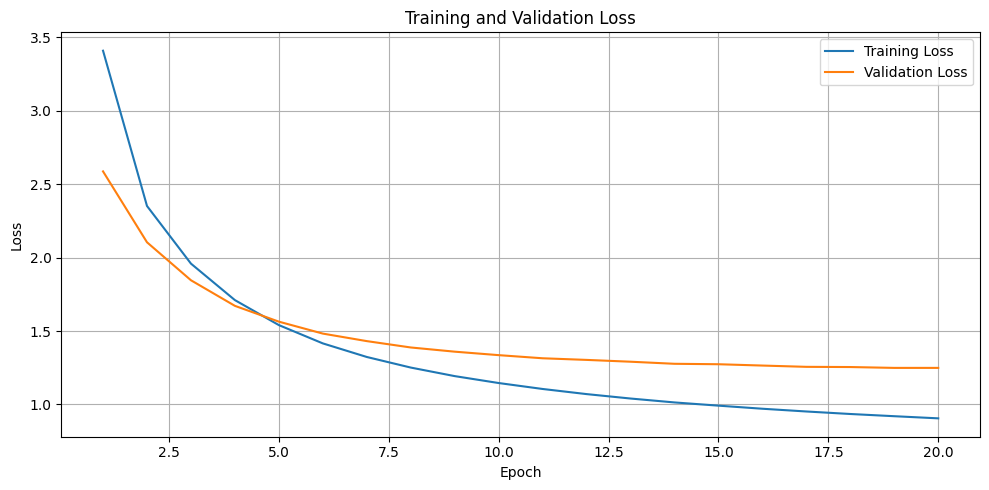

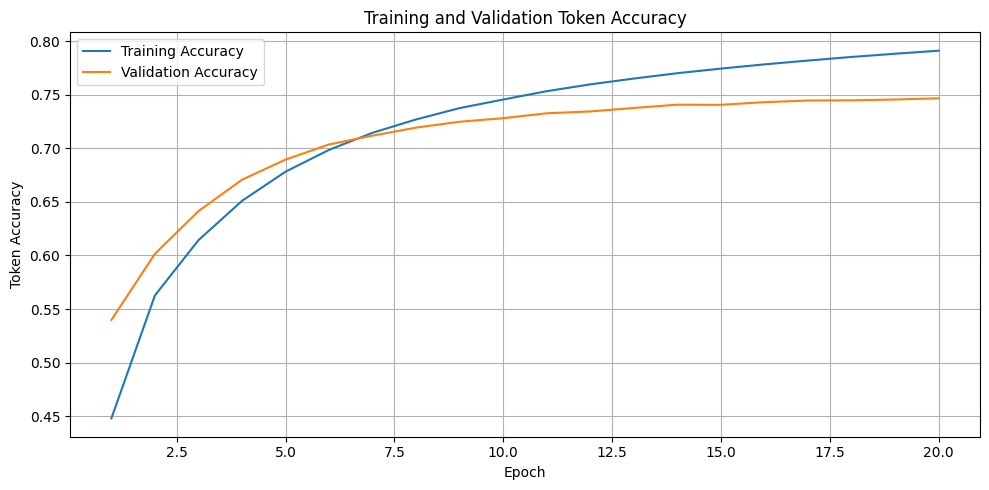

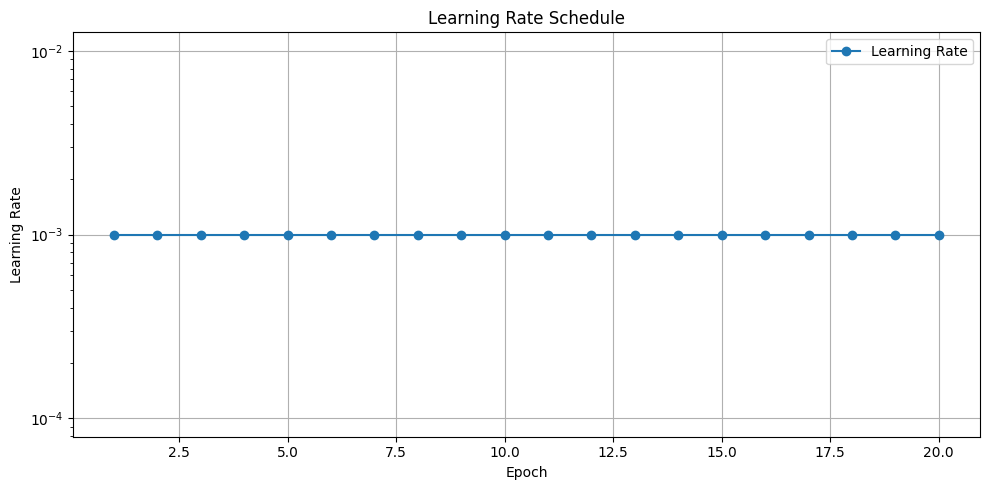

In [23]:
plot_training_history(history_e0)

In [24]:
# ==========================================
# TEST EVALUATION — LSTM E0
# ==========================================

test_results_e0 = evaluate_model(
    model=model,
    test_loader=test_loader,
    criterion=criterion,
    device=device,
    en_pad_id=EN_PAD_ID,
    fr_pad_id=FR_PAD_ID
)

Test Loss: 1.2550
Test Token Accuracy: 74.49%


## Experiment E0: LSTM Baseline — Results and Discussion

### 1. Objective

Experiment E0 established the baseline performance of the LSTM encoder–decoder architecture for English–French machine translation. The model used one LSTM layer in the encoder and one in the decoder, with an embedding dimension of 128 and a hidden dimension of 256.

### 2. Training Results

The model was trained for 20 epochs using Adam with an initial learning rate of 0.001. Training loss decreased from 3.4101 in the first epoch to 0.9056 in the final epoch. Training token accuracy increased from 44.79% to 79.11%.

Validation loss decreased from 2.5878 to 1.2493, while validation token accuracy increased from 53.98% to 74.67%. The learning rate remained at 0.001 throughout training.

### 3. Final Metrics

| Metric | Result |
|---|---:|
| Final training loss | 0.9056 |
| Final validation loss | 1.2493 |
| Final training token accuracy | 79.11% |
| Final validation token accuracy | 74.67% |
| Test loss | 1.2550 |
| Test token accuracy | 74.49% |
| Final learning rate | 0.001 |

### 4. Learning-Curve Analysis

The training loss decreased consistently, indicating that the model continued learning the training data. Validation loss also improved substantially, although its improvement slowed during the later epochs.

The difference between training and validation accuracy at the final epoch was approximately 4.44 percentage points. This suggests a moderate generalization gap.

The learning-rate scheduler did not reduce the learning rate during the run. Although validation loss improvements became small near the end, the model still showed gradual improvements in validation accuracy.

### 5. Test Evaluation

The model achieved a test loss of 1.2550 and a test token accuracy of 74.49%. The test accuracy was close to the final validation accuracy of 74.67%, indicating similar token-level performance on the two data splits.

These metrics were obtained using teacher-forced next-token prediction. They do not directly measure complete-sentence translation quality.

### 6. Conclusion

The LSTM baseline established a reference point for the subsequent architectural experiments. It achieved 74.49% test token accuracy and a test loss of 1.2550.

The learning curves show effective learning, alongside a moderate difference between training and validation performance. The baseline results will be used to assess the effect of increasing recurrent depth in E1 and increasing embedding dimension in E2.

For strict model selection, the best validation checkpoint should be saved and used for final test evaluation. The reported test metrics above correspond to the model weights evaluated at the end of the training run, unless a best-validation checkpoint was explicitly restored beforehand.


In [25]:
# ==========================================
# LSTM EXPERIMENT CONFIGURATION
# ==========================================

# Experiment selection
EXPERIMENT = "E1"

# Data configuration
BATCH_SIZE = 64

# Model configuration
EMBEDDING_DIM = 128
HIDDEN_DIM = 256
NUM_LAYERS = 2
DROPOUT_RATE = 0.2

# Training configuration
NUM_EPOCHS = 20
LEARNING_RATE = 0.001
WEIGHT_DECAY = 1e-5
GRAD_CLIP = 1.0

# Learning-rate scheduler configuration
SCHEDULER_FACTOR = 0.8
SCHEDULER_PATIENCE = 3
MIN_LEARNING_RATE = 1e-6

# Special token IDs
EN_PAD_ID = en_tokenizer.token_to_id("[PAD]")
FR_PAD_ID = fr_tokenizer.token_to_id("[PAD]")
FR_BOS_ID = fr_tokenizer.token_to_id("[BOS]")
FR_EOS_ID = fr_tokenizer.token_to_id("[EOS]")

# Vocabulary sizes
EN_VOCAB_SIZE = en_tokenizer.get_vocab_size()
FR_VOCAB_SIZE = fr_tokenizer.get_vocab_size()

# Device
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print(f"Experiment: {EXPERIMENT}")
print(f"Device: {device}")
print(f"English vocabulary: {EN_VOCAB_SIZE}")
print(f"French vocabulary: {FR_VOCAB_SIZE}")

Experiment: E1
Device: cuda
English vocabulary: 14493
French vocabulary: 23539


In [26]:
# ==========================================
# MODEL INSTANTIATION
# ==========================================

# Encoder
encoder = Encoder(
    vocab_size=EN_VOCAB_SIZE,
    embedding_dim=EMBEDDING_DIM,
    hidden_dim=HIDDEN_DIM,
    num_layers=NUM_LAYERS,
    padding_idx=EN_PAD_ID
)

# Decoder
decoder = Decoder(
    vocab_size=FR_VOCAB_SIZE,
    embedding_dim=EMBEDDING_DIM,
    hidden_dim=HIDDEN_DIM,
    num_layers=NUM_LAYERS,
    padding_idx=FR_PAD_ID,
    dropout_rate=DROPOUT_RATE
)

# Combine encoder and decoder
model = Seq2Seq(
    encoder=encoder,
    decoder=decoder
).to(device)

# Count trainable parameters
total_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

print(model)
print(f"\nExperiment: {EXPERIMENT}")
print(f"Device: {device}")
print(f"Trainable parameters: {total_parameters:,}")

Seq2Seq(
  (encoder): Encoder(
    (embedding): Embedding(14493, 128, padding_idx=1)
    (lstm): LSTM(128, 256, num_layers=2, batch_first=True)
  )
  (decoder): Decoder(
    (embedding): Embedding(23539, 128, padding_idx=1)
    (lstm): LSTM(128, 256, num_layers=2, batch_first=True)
    (dropout): Dropout(p=0.2, inplace=False)
    (fc): Linear(in_features=256, out_features=23539, bias=True)
  )
)

Experiment: E1
Device: cuda
Trainable parameters: 12,760,819


In [27]:
# ==========================================
# TRAINING COMPONENTS — E1
# ==========================================

criterion = nn.CrossEntropyLoss(
    ignore_index=FR_PAD_ID
)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=SCHEDULER_FACTOR,
    patience=SCHEDULER_PATIENCE,
    min_lr=MIN_LEARNING_RATE
)

print("Loss function, optimizer, and scheduler initialized.")

Loss function, optimizer, and scheduler initialized.


In [28]:
# ==========================================
# E1 FORWARD-PASS CHECK
# ==========================================

source_ids, target_ids = next(iter(train_loader))

source_ids = source_ids.to(device)
target_ids = target_ids.to(device)

source_lengths = (
    source_ids != EN_PAD_ID
).sum(dim=1)

decoder_input = target_ids[:, :-1]
expected_targets = target_ids[:, 1:]

model.eval()

with torch.no_grad():
    logits = model(
        source_ids,
        source_lengths,
        decoder_input
    )

print("Source:", source_ids.shape)
print("Decoder input:", decoder_input.shape)
print("Expected targets:", expected_targets.shape)
print("Logits:", logits.shape)

assert logits.shape[:2] == expected_targets.shape
assert logits.shape[-1] == FR_VOCAB_SIZE

print("E1 forward-pass check passed.")

Source: torch.Size([64, 20])
Decoder input: torch.Size([64, 21])
Expected targets: torch.Size([64, 21])
Logits: torch.Size([64, 21, 23539])
E1 forward-pass check passed.


In [29]:
history_e1 = train_model(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    optimizer=optimizer,
    criterion=criterion,
    scheduler=scheduler,
    num_epochs=NUM_EPOCHS,
    en_pad_id=EN_PAD_ID,
    fr_pad_id=FR_PAD_ID,
    device=device
)

Epoch [1/20] Train Loss: 3.5776 | Val Loss: 2.7073 | Train Acc: 42.65% | Val Acc: 52.23% | LR: 0.001
Epoch [2/20] Train Loss: 2.4464 | Val Loss: 2.1888 | Train Acc: 55.40% | Val Acc: 59.25% | LR: 0.001
Epoch [3/20] Train Loss: 2.0170 | Val Loss: 1.8772 | Train Acc: 61.17% | Val Acc: 64.18% | LR: 0.001
Epoch [4/20] Train Loss: 1.7327 | Val Loss: 1.6757 | Train Acc: 65.51% | Val Acc: 67.41% | LR: 0.001
Epoch [5/20] Train Loss: 1.5346 | Val Loss: 1.5430 | Train Acc: 68.68% | Val Acc: 69.64% | LR: 0.001
Epoch [6/20] Train Loss: 1.3941 | Val Loss: 1.4596 | Train Acc: 71.00% | Val Acc: 71.07% | LR: 0.001
Epoch [7/20] Train Loss: 1.2910 | Val Loss: 1.4029 | Train Acc: 72.74% | Val Acc: 72.07% | LR: 0.001
Epoch [8/20] Train Loss: 1.2098 | Val Loss: 1.3553 | Train Acc: 74.08% | Val Acc: 72.94% | LR: 0.001
Epoch [9/20] Train Loss: 1.1464 | Val Loss: 1.3177 | Train Acc: 75.20% | Val Acc: 73.50% | LR: 0.001
Epoch [10/20] Train Loss: 1.0933 | Val Loss: 1.3024 | Train Acc: 76.16% | Val Acc: 73.78% |

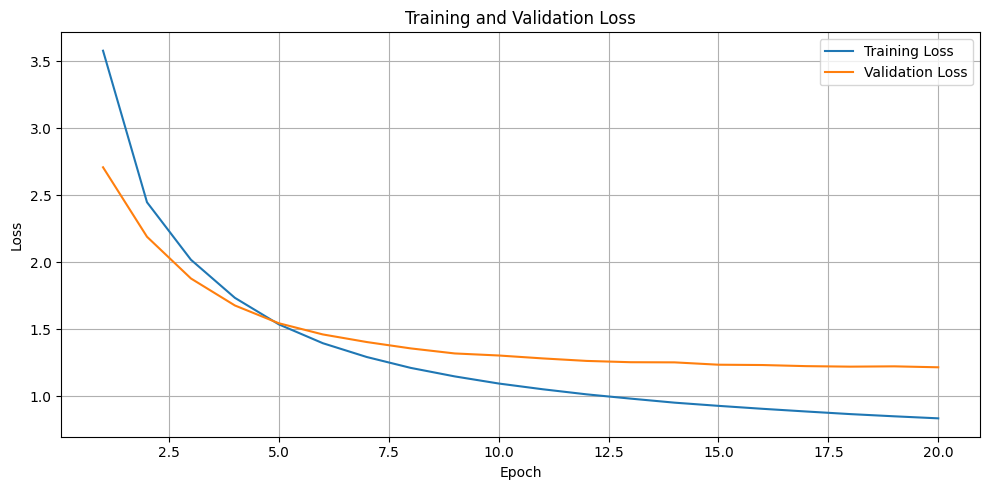

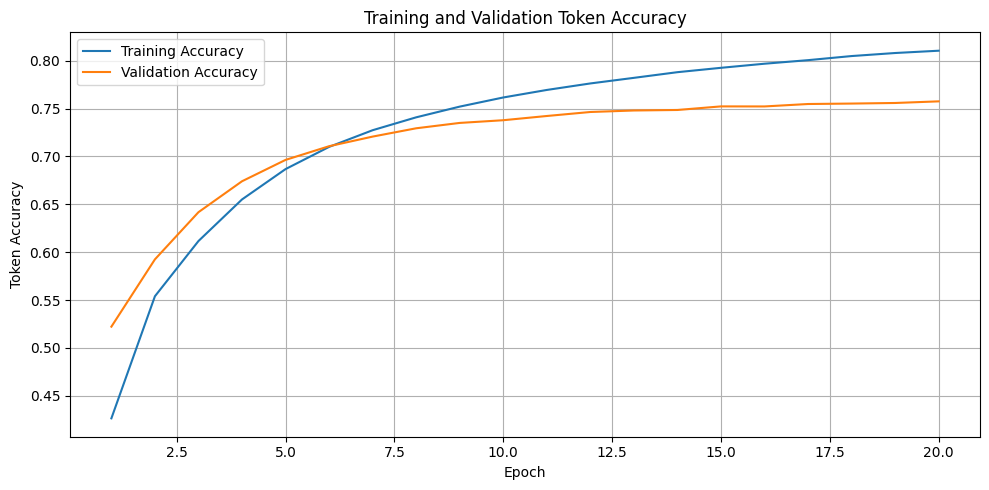

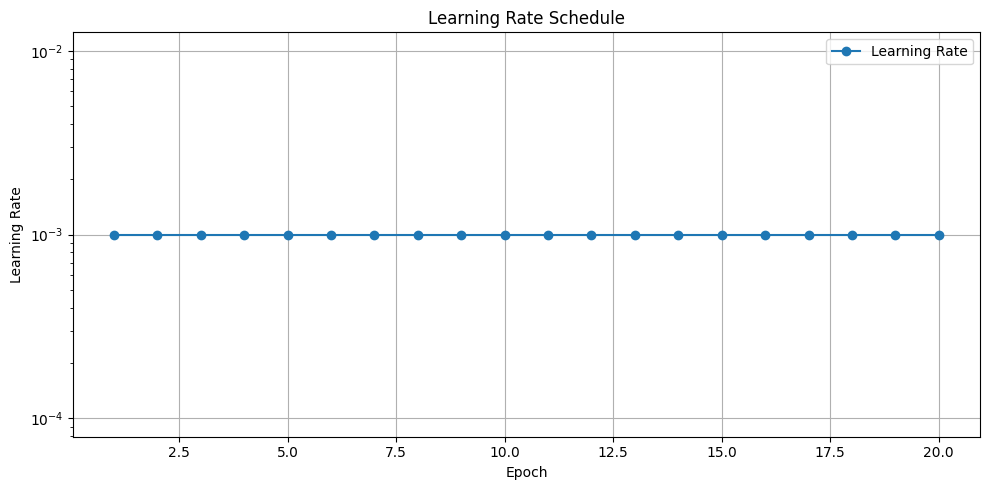

In [30]:
plot_training_history(history_e1)

In [31]:
test_results_e1 = evaluate_model(
    model=model,
    test_loader=test_loader,
    criterion=criterion,
    device=device,
    en_pad_id=EN_PAD_ID,
    fr_pad_id=FR_PAD_ID
)

Test Loss: 1.2164
Test Token Accuracy: 75.85%


## Experiment E1: LSTM Depth Experiment — Results and Discussion

### 1. Objective

Experiment E1 investigated the effect of increasing the recurrent depth of the LSTM encoder–decoder architecture. Both the encoder and decoder were increased from one LSTM layer to two, while the embedding dimension, hidden dimension, and training configuration were kept unchanged from E0.

### 2. Training Results

The model was trained for 20 epochs. Training loss decreased from 3.5776 to 0.8333, while validation loss decreased from 2.7073 to 1.2143.

Training token accuracy increased from 42.65% to 81.04%, and validation token accuracy increased from 52.23% to 75.75%. The learning rate remained at 0.001 throughout the run.

### 3. Final Metrics

| Metric | Result |
|---|---:|
| Final training loss | 0.8333 |
| Final validation loss | 1.2143 |
| Final training token accuracy | 81.04% |
| Final validation token accuracy | 75.75% |
| Test loss | 1.2164 |
| Test token accuracy | 75.85% |
| Final learning rate | 0.001 |

### 4. Learning-Curve Analysis

Training loss decreased consistently throughout the experiment. Validation loss also decreased, with improvements becoming smaller during the later epochs.

The difference between final training and validation token accuracy was 5.29 percentage points. This indicates a generalization gap, although validation performance continued to improve and the curves do not show a strong late-stage increase in validation loss.

### 5. Test Evaluation

The model achieved a test loss of 1.2164 and a test token accuracy of 75.85%. These results were better than the E0 test loss of 1.2550 and test token accuracy of 74.49%.

The observed improvement suggests that increasing both encoder and decoder depth benefited token-level prediction under the tested configuration. However, the experiment does not establish that additional depth will always improve translation performance.

### 6. Comparison with E0

Compared with the baseline, E1 increased test token accuracy by 1.36 percentage points and reduced test loss by 0.0386.

Validation token accuracy increased by 1.08 percentage points, while validation loss decreased by 0.0350. These results provide evidence that the two-layer configuration performed better than the one-layer baseline in this experiment.

### 7. Conclusion

Experiment E1 showed a modest improvement over E0 after increasing the number of LSTM layers in both the encoder and decoder from one to two.

The model achieved 75.85% test token accuracy and a test loss of 1.2164. These results will serve as the basis for comparison with E2, which will increase the embedding dimension while returning to one layer in each component.

The reported test metrics correspond to the model weights evaluated after the final training epoch. A best-validation checkpoint should be used in future runs to ensure consistent model selection.


In [32]:
# ==========================================
# LSTM EXPERIMENT CONFIGURATION
# ==========================================

# Experiment selection
EXPERIMENT = "E2"

# Data configuration
BATCH_SIZE = 64

# Model configuration
EMBEDDING_DIM = 256
HIDDEN_DIM = 256
NUM_LAYERS = 1
DROPOUT_RATE = 0.2

# Training configuration
NUM_EPOCHS = 20
LEARNING_RATE = 0.001
WEIGHT_DECAY = 1e-5
GRAD_CLIP = 1.0

# Learning-rate scheduler configuration
SCHEDULER_FACTOR = 0.8
SCHEDULER_PATIENCE = 3
MIN_LEARNING_RATE = 1e-6

# Special token IDs
EN_PAD_ID = en_tokenizer.token_to_id("[PAD]")
FR_PAD_ID = fr_tokenizer.token_to_id("[PAD]")
FR_BOS_ID = fr_tokenizer.token_to_id("[BOS]")
FR_EOS_ID = fr_tokenizer.token_to_id("[EOS]")

# Vocabulary sizes
EN_VOCAB_SIZE = en_tokenizer.get_vocab_size()
FR_VOCAB_SIZE = fr_tokenizer.get_vocab_size()

# Device
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print(f"Experiment: {EXPERIMENT}")
print(f"Device: {device}")
print(f"English vocabulary: {EN_VOCAB_SIZE}")
print(f"French vocabulary: {FR_VOCAB_SIZE}")

Experiment: E2
Device: cuda
English vocabulary: 14493
French vocabulary: 23539


In [33]:
# ==========================================
# MODEL INSTANTIATION
# ==========================================

# Encoder
encoder = Encoder(
    vocab_size=EN_VOCAB_SIZE,
    embedding_dim=EMBEDDING_DIM,
    hidden_dim=HIDDEN_DIM,
    num_layers=NUM_LAYERS,
    padding_idx=EN_PAD_ID
)

# Decoder
decoder = Decoder(
    vocab_size=FR_VOCAB_SIZE,
    embedding_dim=EMBEDDING_DIM,
    hidden_dim=HIDDEN_DIM,
    num_layers=NUM_LAYERS,
    padding_idx=FR_PAD_ID,
    dropout_rate=DROPOUT_RATE
)

# Combine encoder and decoder
model = Seq2Seq(
    encoder=encoder,
    decoder=decoder
).to(device)

# Count trainable parameters
total_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

print(model)
print(f"\nExperiment: {EXPERIMENT}")
print(f"Device: {device}")
print(f"Trainable parameters: {total_parameters:,}")

Seq2Seq(
  (encoder): Encoder(
    (embedding): Embedding(14493, 256, padding_idx=1)
    (lstm): LSTM(256, 256, batch_first=True)
  )
  (decoder): Decoder(
    (embedding): Embedding(23539, 256, padding_idx=1)
    (lstm): LSTM(256, 256, batch_first=True)
    (dropout): Dropout(p=0.2, inplace=False)
    (fc): Linear(in_features=256, out_features=23539, bias=True)
  )
)

Experiment: E2
Device: cuda
Trainable parameters: 16,838,387


In [34]:
# ==========================================
# TRAINING COMPONENTS — E2
# ==========================================

criterion = nn.CrossEntropyLoss(
    ignore_index=FR_PAD_ID
)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=SCHEDULER_FACTOR,
    patience=SCHEDULER_PATIENCE,
    min_lr=MIN_LEARNING_RATE
)

print("Loss function, optimizer, and scheduler initialized.")

Loss function, optimizer, and scheduler initialized.


In [35]:
# ==========================================
# E2 FORWARD-PASS CHECK
# ==========================================

source_ids, target_ids = next(iter(train_loader))

source_ids = source_ids.to(device)
target_ids = target_ids.to(device)

source_lengths = (
    source_ids != EN_PAD_ID
).sum(dim=1)

decoder_input = target_ids[:, :-1]
expected_targets = target_ids[:, 1:]

model.eval()

with torch.no_grad():
    logits = model(
        source_ids,
        source_lengths,
        decoder_input
    )

print("Source:", source_ids.shape)
print("Decoder input:", decoder_input.shape)
print("Expected targets:", expected_targets.shape)
print("Logits:", logits.shape)

assert logits.shape[:2] == expected_targets.shape
assert logits.shape[-1] == FR_VOCAB_SIZE

print("E1 forward-pass check passed.")

Source: torch.Size([64, 20])
Decoder input: torch.Size([64, 21])
Expected targets: torch.Size([64, 21])
Logits: torch.Size([64, 21, 23539])
E1 forward-pass check passed.


In [36]:
history_e1 = train_model(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    optimizer=optimizer,
    criterion=criterion,
    scheduler=scheduler,
    num_epochs=NUM_EPOCHS,
    en_pad_id=EN_PAD_ID,
    fr_pad_id=FR_PAD_ID,
    device=device
)

Epoch [1/20] Train Loss: 3.2325 | Val Loss: 2.4396 | Train Acc: 46.86% | Val Acc: 55.86% | LR: 0.001
Epoch [2/20] Train Loss: 2.1982 | Val Loss: 1.9530 | Train Acc: 58.56% | Val Acc: 62.80% | LR: 0.001
Epoch [3/20] Train Loss: 1.7980 | Val Loss: 1.6933 | Train Acc: 64.16% | Val Acc: 66.92% | LR: 0.001
Epoch [4/20] Train Loss: 1.5581 | Val Loss: 1.5443 | Train Acc: 67.84% | Val Acc: 69.43% | LR: 0.001
Epoch [5/20] Train Loss: 1.4005 | Val Loss: 1.4507 | Train Acc: 70.33% | Val Acc: 70.91% | LR: 0.001
Epoch [6/20] Train Loss: 1.2895 | Val Loss: 1.3920 | Train Acc: 72.18% | Val Acc: 71.90% | LR: 0.001
Epoch [7/20] Train Loss: 1.2085 | Val Loss: 1.3439 | Train Acc: 73.54% | Val Acc: 72.77% | LR: 0.001
Epoch [8/20] Train Loss: 1.1450 | Val Loss: 1.3121 | Train Acc: 74.63% | Val Acc: 73.27% | LR: 0.001
Epoch [9/20] Train Loss: 1.0953 | Val Loss: 1.2949 | Train Acc: 75.50% | Val Acc: 73.65% | LR: 0.001
Epoch [10/20] Train Loss: 1.0548 | Val Loss: 1.2817 | Train Acc: 76.21% | Val Acc: 73.91% |

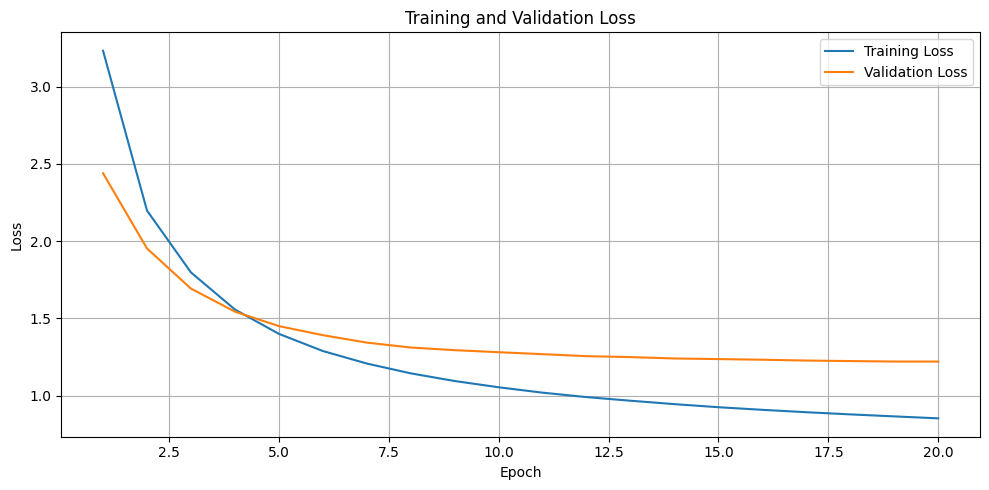

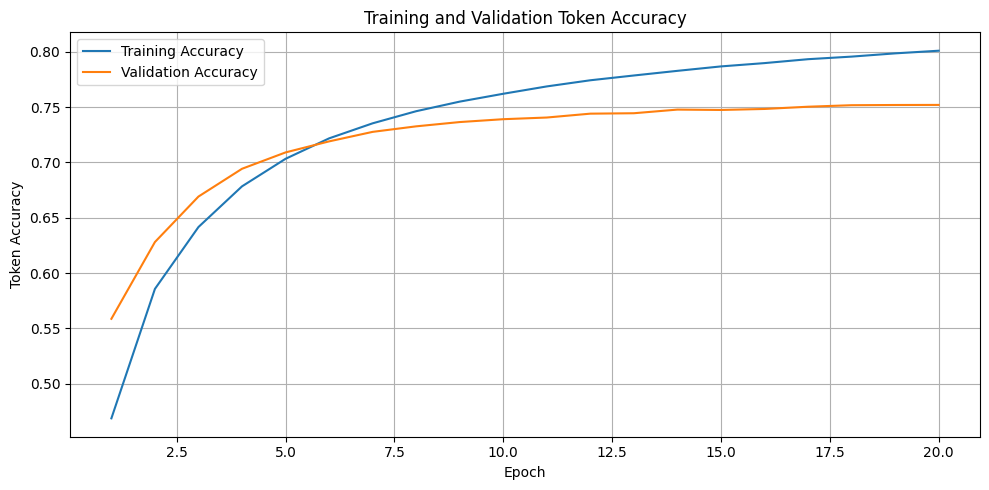

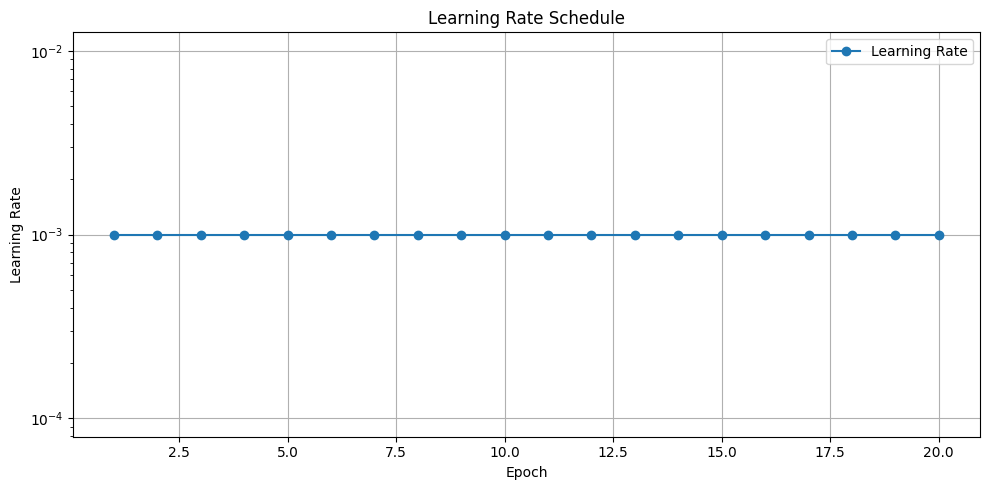

In [37]:
plot_training_history(history_e1)

In [38]:
test_results_e2 = evaluate_model(
    model=model,
    test_loader=test_loader,
    criterion=criterion,
    device=device,
    en_pad_id=EN_PAD_ID,
    fr_pad_id=FR_PAD_ID
)

Test Loss: 1.2239
Test Token Accuracy: 75.14%


## Experiment E2: LSTM Embedding-Dimension Experiment — Results and Discussion

### 1. Objective

Experiment E2 investigated the effect of increasing the embedding dimension from 128 to 256 while maintaining a hidden dimension of 256 and one LSTM layer in each of the encoder and decoder.

The experiment followed the same dataset, preprocessing, training procedure, and evaluation method used in E0 and E1.

### 2. Training Results

The model was trained for 20 epochs. Training loss decreased from 3.2325 to 0.8538, while validation loss decreased from 2.4396 to 1.2211.

Training token accuracy increased from 46.86% to 80.11%, and validation token accuracy increased from 55.86% to 75.20%. The learning rate remained at 0.001 throughout training.

### 3. Final Metrics

| Metric | Result |
|---|---:|
| Final training loss | 0.8538 |
| Final validation loss | 1.2211 |
| Final training token accuracy | 80.11% |
| Final validation token accuracy | 75.20% |
| Test loss | 1.2239 |
| Test token accuracy | 75.14% |
| Final learning rate | 0.001 |

### 4. Learning-Curve Analysis

Training loss decreased consistently, indicating that the model learned the training data. Validation loss also decreased, although improvements became smaller during the later epochs.

The difference between final training and validation token accuracy was 4.91 percentage points. This indicates a generalization gap between the training and validation sets.

### 5. Test Evaluation

The model achieved a test loss of 1.2239 and a test token accuracy of 75.14%. These results improved upon the E0 baseline, which achieved a test loss of 1.2550 and a test token accuracy of 74.49%.

However, E2 did not outperform E1, which achieved a test loss of 1.2164 and a test token accuracy of 75.85%.

### 6. Comparison with E0 and E1

Increasing the embedding dimension from 128 to 256 improved test token accuracy by 0.65 percentage points relative to E0. Compared with E1, E2 had a test token accuracy lower by 0.71 percentage points.

The results suggest that increasing the embedding dimension provided a modest improvement over the baseline in this experiment, while increasing recurrent depth produced the strongest observed test performance among the three configurations.

### 7. Conclusion

Experiment E2 completed the planned LSTM embedding-dimension experiment. The model achieved 75.14% test token accuracy and a test loss of 1.2239.

The three LSTM experiments are now complete. Their results provide a practical basis for studying how recurrent depth and embedding dimension affect model behavior. The next stage is to implement translation inference, beginning with greedy decoding and followed by beam search, using the existing trained LSTM model.

The reported test metrics correspond to the model weights evaluated after the final training epoch, unless a best-validation checkpoint was explicitly restored beforehand.


In [39]:
%cd /content/drive/MyDrive/english-french-machine-translation/english-french-machine-translation

!git status
!git remote -v

/content/drive/MyDrive/english-french-machine-translation/english-french-machine-translation
Refresh index: 100% (15/15), done.
On branch main
Your branch is up to date with 'origin/main'.

Changes not staged for commit:
  (use "git add <file>..." to update what will be committed)
  (use "git restore <file>..." to discard changes in working directory)
	modified:   notebooks/02_gru_translation.ipynb
	modified:   notebooks/03_lstm_translation.ipynb

no changes added to commit (use "git add" and/or "git commit -a")
origin	https://github.com/davidmba819/english-french-machine-translation.git (fetch)
origin	https://github.com/davidmba819/english-french-machine-translation.git (push)
